# 14 项目优化与项目总结


## 资料来源与当天目标

本篇对应百度网盘14天规划的 **day14 项目优化 项目总结**，也是「学成在线项目」系列最后一篇。前13篇已经按课程顺序整理内容、媒资、搜索、认证授权、选课支付、在线学习和部署；本篇先完成课程查询的性能优化，再把整个项目的技术与业务闭环串起来。

本次已核验day14目录，并阅读以下资料：

- `第八章 项目优化3.1.docx`，本地文件名为 `第八章+项目优化3.1.docx`：压测、日志、Redis缓存、缓存穿透/雪崩/击穿、本地锁、Redis分布式锁、Redisson。
- `项目总结.docx`：业务介绍、微服务与中间件、研发协作、内容发布、媒资、认证授权、选课支付、项目复盘。文内标题写作“第7章 项目总结”，应按文件和内容区分，不能与第13篇的“第七章 项目部署”混淆。
- day14配套的 `singleServerConfig.yaml`、`clusterServersConfig.yaml`：已下载并静态阅读，用于核对Redisson连接、线程和编解码配置。

两份讲义复用此前从同一分享下载的版本，已核验本日文件列表与来源哈希。day14还提供 `apache-jmeter-5.5.zip` 和约114.4MB的 `xuecheng-plus-project.zip`；源码包网页提示“下载内容超限，请使用百度网盘客户端下载”，**本次未取得该包**。因此本篇明确区分“讲义代码”“校正示例/补充设计”和“后续实践检查”，不宣称本日完整工程已实现或测试通过。

本文内嵌16张讲义原图。所有代码放在Markdown中用于阅读；没有执行压测、SQL、支付请求、锁实验或课程服务，没有安装JMeter、启动中间件、改动hosts/Nacos或旧笔记。文中的吞吐量是课堂结果，不是本机实测；地址和凭据以本地示例或占位符表达。

学习主线：**同一入口建立基线 → 定位瓶颈 → 引入缓存 → 处理空值与过期 → 控制并发回源 → 明确一致性与失败边界 → 复盘全项目。**


## 1. 优化对象与请求路径：先确定测量的是哪一个接口

讲义的优化需求是查询课程详情：用户访问门户，读取已发布课程信息及课程计划。课程发布后读多写少，重复请求相同课程，是适合引入缓存的场景。

```text
浏览器/压测机
  → Nginx门户入口
  → Gateway（是否经过：以当前路由为准）
  → 内容管理服务Controller
  → 查询已发布CoursePublish
  → Redis命中；或数据库回源并回填
```

讲义开头的压测地址是 `http://www.51xuecheng.cn/open/content/course/whole/{courseId}`，后面Controller片段使用 `/course/whole/{courseId}`。这些是不同层的路径表达，不能直接把浏览器完整路径写到Controller，也不能未经核对就认定两个地址一定指向相同查询。

实践时逐层记录：浏览器路径、Nginx的proxy_pass、Gateway的匹配规则和前缀处理、服务context-path、Controller映射。压测请求与改动的缓存方法必须对应同一入口、同一数据源和同一发布版本。

**课程预览与正式课程详情要区分**：机构预览可以读取编辑草稿；公开详情和正式学习应按业务规则读取发布快照。把草稿查询优化得更快，不能代替验证正式发布链路。


## 2. 性能指标：吞吐量、延迟、错误率要一起看

| 指标 | 含义与读法 | 常见误解 |
| --- | --- | --- |
| 并发请求/线程 | 某时刻执行或等待的请求/压测线程数 | 200线程等于200TPS |
| QPS | 在选定统计边界内，每秒查询或请求数 | 所有系统都有统一QPS口径 |
| TPS | 每秒完成的业务事务数，需定义一笔事务包含什么 | 业务事务必然等于数据库事务 |
| 平均响应时间 | 请求耗时总和除以样本数 | 平均值低就没有慢请求 |
| p95/p99 | 95%/99%的请求耗时不超过该值 | 尾部延迟可以用平均值替代 |
| 错误率 | 失败样本数占全部样本的比例 | 吞吐量高就代表成功处理多 |
| 资源指标 | CPU、内存、GC、IO、网络、连接池等 | CPU低说明系统一定有余量 |

例如一个业务操作对外是1次请求，但内部又调用1个服务，入口QPS和内部调用数并不相同。讲义用“内部远程一次，所以QPS=2TPS”帮助理解调用数量，**不能作为通用公式**；应先说明统计边界和一笔业务包含的请求。

在稳定负载、同一边界下，可以用Little定律粗略理解 `系统内平均请求数 ≈ 吞吐量 × 平均耗时`。例如100次/秒、平均0.2秒，大约有20个请求在系统内；这不是对所有突发和非稳定流量的精确预测。

讲义给出的CPU/内存85%、网络80%等是课堂观察参考。实际SLO要根据响应目标、硬件、GC、故障余量与成本确定，不能把参考比例当作放行标准。


## 3. JMeter计划：先固定条件，再增加负载

讲义用JMeter压测，示例为 **200个线程，每个执行100次，共20,000个请求**。循环次数决定总样本数，线程数决定压测端并发执行能力；它们不能直接换算成“一万在线用户”。

一次可复现的计划至少包含：

1. 线程组：线程数、启动时间Ramp-up、循环次数或持续时间。
2. HTTP请求：协议、地址、端口、路径、参数，与真实入口一致。
3. 参数化数据：热门课程、普通课程、不存在课程；固定单个ID仅覆盖热点场景。
4. 断言：HTTP成功之外，还检查业务响应、课程ID和必要字段；返回空数据或错误页面不能算有效成功。
5. 汇总结果：聚合报告、错误样本和原始结果，结合服务端监控。

压测前完成小流量功能校验、预热，并明确是在测“冷缓存”“热缓存”还是“热点过期”。一次只改变一个因素；比较日志级别时保持入口、线程、数据和服务副本数一致。

压测机与被测服务尽量分离，避免JMeter客户端、GUI监听器或磁盘写结果成为瓶颈。大流量实践可使用非GUI模式，以下只展示离线学习命令，需在具备授权的隔离环境中执行：

```text
jmeter -n -t course-query.jmx -l results.jtl -e -o report-day14
```

计划文件、结果目录和服务器配置应与报告一起留档。本次没有安装或执行JMeter，也没有向课程站点或本机服务发起压力请求。


## 4. 聚合报告：把结果与条件绑定

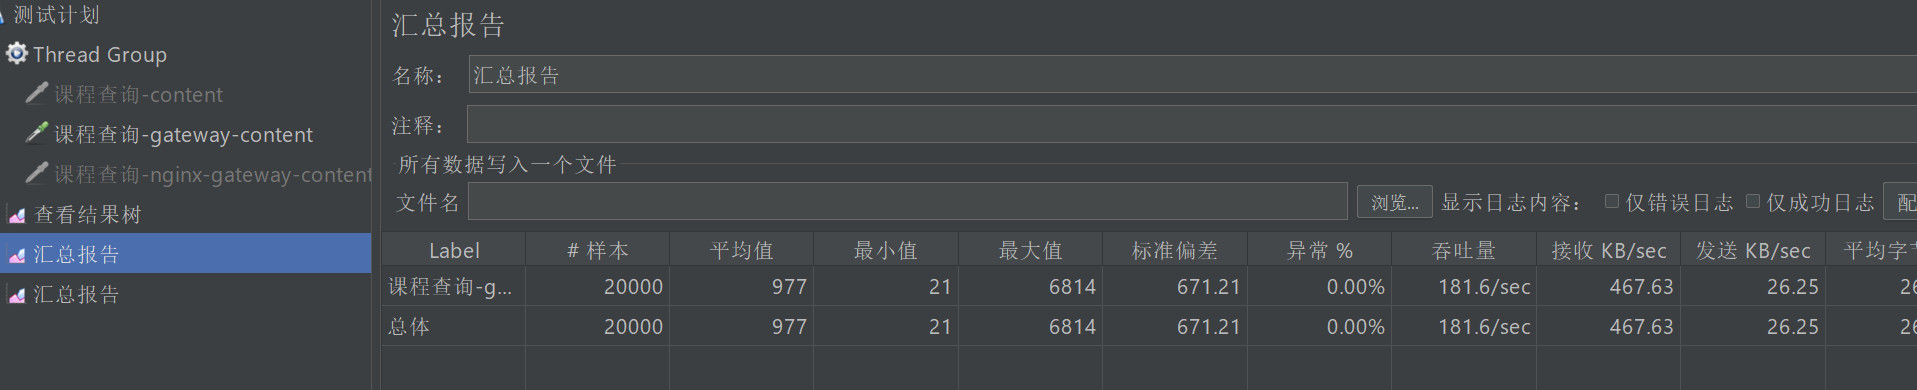

讲义先经过Gateway访问content，再直连content，观察吞吐量差异。聚合报告中的Samples是样本数，Average/Min/Max是耗时统计，Error%是失败比例，Throughput是报告时间范围内的吞吐量。

读报告要核对时间单位：同一个Throughput数值可能按秒或分钟显示。总请求数除以测试持续时间只能得到粗略整体吞吐量，还要注意启动阶段、预热阶段和稳定阶段。

建议记录以下比较表，未测的数据留空，不用讲义数字填充个人实验结果：

| 维度 | 基线与优化后都要记录 |
| --- | --- |
| 版本/环境 | 应用版本、JDK、中间件版本、硬件、服务副本数 |
| 入口 | 完整请求路径，是否经过Nginx/Gateway |
| 负载 | 线程、启动时间、持续时间、ID分布、请求速率 |
| 缓存 | 是否预热、TTL、缓存命中率、过期比例 |
| 结果 | 成功吞吐量、p95/p99、错误率和响应正确性 |
| 资源 | CPU/GC、数据库耗时、连接池等待、Redis延迟、网络 |

直连提升只能提示额外链路可能有开销。若两轮命中率、日志、负载或连接复用不同，不能把全部差异归因于Gateway。


## 5. 先定位瓶颈：日志只是一个可能原因

讲义在课程查询中打印数据库访问标记，并比较DEBUG和INFO日志级别。SQL日志、对象序列化、同步控制台输出或磁盘写入可能显著降低吞吐量；将日志级别调为INFO后，课堂结果明显改善。

排查顺序可以是：入口耗时 → 网关/远程调用 → Service → SQL → 序列化/返回。围绕慢点采集证据：慢SQL及执行计划、连接池排队、线程栈、GC停顿、Redis命中率与命令耗时、日志队列和磁盘IO。

```yaml
# 仅示意日志层级；按工程实际包名和配置来源调整。
logging:
  level:
    root: INFO
    com.xuecheng: INFO
```

配置可能来自本地文件或Nacos，修改后是否生效要看实际加载规则。不能只编辑一份没有被当前服务加载的配置。

减少无用DEBUG、逐请求println与大对象日志，同时保留必要错误、业务审计和关联ID。敏感数据与真实令牌不应写入日志。若异步日志队列满导致阻塞或丢弃，还需明确策略；“关闭全部日志”会妨碍故障定位。


## 6. 讲义的优化结果：理解趋势，不当作性能承诺

| 课堂步骤 | 讲义中的约吞吐量 | 说明 |
| --- | --- | --- |
| Gateway + content查询 | 180次/秒 | 起始观察 |
| 直连content | 300次/秒 | 入口和链路改变 |
| 减少DEBUG，使用INFO | 1500次/秒 | 日志开销明显 |
| 加入Redis缓存 | 2700次/秒 | 减少重复数据库查询 |
| 整个查询包在synchronized中 | 1300次/秒 | 命中缓存的请求也排队 |
| 先读缓存，miss后加锁并二次检查 | 3800次/秒 | 锁只参与缓存重建 |

这些数字来自讲义的不同实验阶段，**不是本次测量，也不是Redis或Redisson的固定上限**。不能简单串成“所有场景提升21倍”的结论；需看环境、入口、命中率、负载和错误率是否可比。

核心经验是：先消除有证据的热点开销，再减少回源，再把锁限制在必要区域。优化命中路径后，还要验证冷启动、热点过期、缓存不可用、慢SQL和多实例场景。热缓存的高吞吐量无法说明失效瞬间仍稳定。


## 7. Redis缓存设计：缓存发布数据，明确key与value

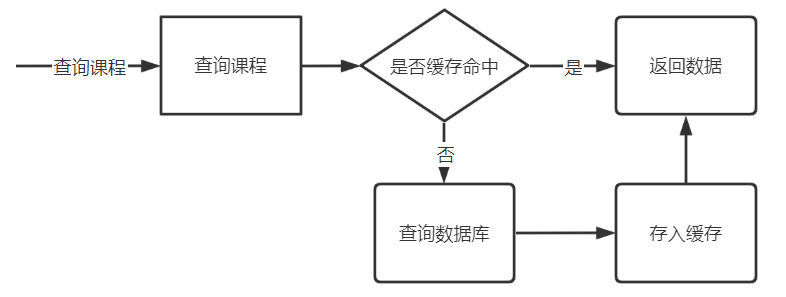

讲义采用Cache-Aside：应用先读Redis；未命中时查数据库，把结果序列化后回填。数据库是持久化事实来源，Redis承担可重建的读取副本。

| 项目 | 讲义/建议含义 |
| --- | --- |
| 数据key | `course:` + courseId，例如 `course:100` |
| value | CoursePublish的JSON，包含已发布课程信息及课程计划 |
| 命中 | 有正缓存或明确的负缓存，直接返回相应结果 |
| miss | Redis中不存在该key，需要回源 |
| 负缓存 | 表示数据库没有公开可访问的发布记录，讲义使用字符串`null` |
| 锁key | `coursequerylock:` + courseId，与数据key区分 |

共享发布信息可按courseId缓存；机构编辑数据要考虑机构归属、审核状态和版本。个人课表、订单等用户数据通常要带userId与相应授权，不能因为key存在就跳过权限校验。

实际工程还需考虑环境前缀、序列化兼容、最大value、Redis连接池和内存策略。课程计划很大时，单个JSON可能增加网络与解析成本；缓存收益需要用端到端数据证明。


## 8. 第一版Cache-Aside：能减少查询，但还不完整

下面是按讲义整理的基础片段，使用StringRedisTemplate，**并非day14工程源码核验结果**。为说明问题，先保留“只缓存查到的数据、不设置TTL”的简单写法：

```java
public CoursePublish getCoursePublishCache(Long courseId) {
    String key = "course:" + courseId;
    String cached = stringRedisTemplate.opsForValue().get(key);
    if (cached != null) {
        return JSON.parseObject(cached, CoursePublish.class);
    }

    CoursePublish data = getCoursePublish(courseId);
    if (data != null) {
        stringRedisTemplate.opsForValue().set(key, JSON.toJSONString(data));
    }
    return data;
}
```

`getCoursePublish`在这里表示查询公开发布快照的业务方法，不能自动替换为草稿预览方法。片段省略了依赖声明和异常处理，不能直接当作完整类运行。

这版有三类缺口：不存在的课程每次都回源；缓存不会自动过期，更新/下架可能仍返回旧值；多个实例同时miss时仍会同时查数据库。后面的空值缓存、TTL、按key重建锁分别解决不同问题，不能用其中一个代替全部。

正常的“数据库无记录”和“数据库查询失败”要区别：超时或连接异常不能当成课程不存在并写入负缓存。


## 9. TTL必须读代码：本章示例与总结方案不同

| 来源/阶段 | 文档中的实际期限 | 需要注意 |
| --- | --- | --- |
| 初始缓存 | 未设置TTL | 需要单独处理更新和失效 |
| 穿透示例 | 正/负缓存都设置30秒 | 注释写300，调用参数是30 |
| 雪崩示例 | 300 + 随机0—99秒 | 分散过期时间 |
| 最终Redisson示例 | 1天 | 查询到null也可能被写入同样期限 |
| 项目总结方案 | 发布课程/视频7天；个人课表/订单5分钟；验证码30秒 | 是总结文档的配置建议，不能证明所有实际代码都如此 |

**不把这些不同阶段的TTL拼成唯一的工程事实**。正缓存、负缓存和锁的TTL也不是同一个概念：正缓存影响数据新鲜度，负缓存影响新数据何时可见，锁期限影响竞争与崩溃恢复。

一个学习用的合理起点是：正缓存300—399秒，负缓存30秒，并在发布/下架后主动失效；热门课程可结合业务做预热。具体数值需根据更新频率、数据库余量、负载和一致性目标决定。

缓存不存在可能来自自然过期、内存淘汰、主动删除、实例故障或key变更。只考虑定时过期不足以设计回源能力。


## 10. 缓存穿透：不存在的数据也要控制回源

穿透是查询本来就不存在或不应公开的数据，缓存和数据库都无法提供有效记录，反复请求持续穿过缓存。例如不断请求不存在的课程ID。

处理可分三层：入口校验ID格式/范围及访问规则；短负缓存；必要时用限流和布隆过滤降低随机无效请求。格式合法并不代表数据存在；存在性判断也不能暴露不应公开的资源。

以下是校正片段：正/负缓存分开TTL，首次读取明确识别负缓存。JSON是文本存储，避免把字符串`"null"`与Redis不存在的Java null混淆。

```java
public CoursePublish getWithNegativeCache(Long courseId) {
    if (courseId == null || courseId <= 0) {
        throw new IllegalArgumentException("课程ID不合法");
    }
    String key = "course:" + courseId;
    String cached = stringRedisTemplate.opsForValue().get(key);
    if (cached != null) {
        return "null".equals(cached)
                ? null : JSON.parseObject(cached, CoursePublish.class);
    }

    CoursePublish data = getCoursePublish(courseId);
    long ttlSeconds = data == null ? 30L
            : 300L + ThreadLocalRandom.current().nextInt(100);
    String payload = data == null ? "null" : JSON.toJSONString(data);
    stringRedisTemplate.opsForValue().set(
            key, payload, ttlSeconds, TimeUnit.SECONDS);
    return data;
}
```

这段仍没有解决并发miss，也省略了Redis故障策略，后文继续完善。公开查询没有记录时，Controller按约定返回不存在/不可访问响应，避免把null当成一条正常课程。

负缓存有时效代价：原本不存在的课程刚发布时，旧负缓存仍可能挡住读取。因此发布成功后也要失效负缓存；短TTL只减少影响窗口，不能代替更新通知。


## 11. 布隆过滤器：快速排除无效ID，但需要同步

布隆过滤器用位数组和多个哈希函数记录集合。添加课程ID时把若干位置设为1；查询时，只要任一位置为0就判断不在集合，全部为1则判断“可能存在”。

```text
请求courseId → 入口校验 → 布隆判断
  不在集合：按完整同步的集合规则直接拒绝/返回不存在
  可能存在：继续查Redis → miss后查数据库
```

阳性可能误判，因为多个ID会共享位；过滤器不是数据库，也无法返回课程内容。阴性可靠依赖“应允许访问的ID已经完整写入集合”：如果新课程未同步，就可能把真实存在的课程错误拒绝。

发布、下架和过滤器重建要设计同步流程。标准布隆过滤器通常不支持安全地直接清零删除，因为可能破坏其他ID的记录；计数布隆等变体可以支持删除，所以不能笼统说“所有布隆过滤器都无法删除”。

选择预计元素量和误判率会影响内存与哈希次数。若有效课程量有限、无效访问很少，短负缓存和入口限流可能已足够；引入布隆之前先验证收益，避免增加难以维护的同步链路。


## 12. 缓存雪崩：大量失效或缓存不可用

雪崩常见于大量key在接近时间过期，或Redis整体不可用，许多请求同时回源造成数据库过载。它与单个热点key击穿、反复查询不存在数据的穿透应分别定位。

| 原因 | 处理思路 | 局限 |
| --- | --- | --- |
| 大量key同一TTL、同时写入 | 基础TTL + 随机抖动，分批预热 | 无法应对Redis整体故障 |
| 发布活动引发集中冷启动 | 提前预热热点、控制重建并发 | 预热数据要符合实际发布版本 |
| Redis连接超时/不可用 | 熔断缓存调用、有界回源、限流降级 | 所有请求无界查库仍会雪崩 |
| 内存淘汰导致命中率降低 | 监控内存与淘汰策略，评估容量 | 增内存不能解决慢SQL或大value |

讲义雪崩示例可表示为：

```java
long ttlSeconds = 300L + ThreadLocalRandom.current().nextInt(100);
```

随机TTL分散失效时间，不能防止所有突发。回源应有超时、并发上限和速率限制；Redis故障时不能为了维持成功率而把数据库连接池打满。

公开课程详情可以按产品策略短暂展示允许使用的旧发布数据；订单、支付确认与收费权益不能因为缓存故障就默认成功或放行。高可用Redis降低故障概率，也不意味着应用可以省略失败处理。


## 13. 缓存击穿：一个热点过期，引发集中回源

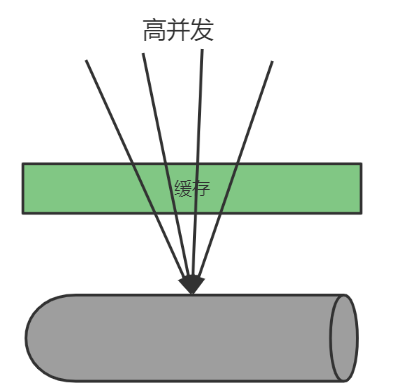

击穿针对单个热点key：大量请求平时命中同一门课程，过期瞬间都发现miss，于是同时查询数据库。真实存在的数据首次冷启动产生并发miss，也可能需要防止重复回源，但不应把它全部称为“查询不存在数据的穿透”。

重建互斥的基本流程：

```text
先读缓存
  命中 → 返回
  miss → 竞争课程对应的重建锁
    获锁 → 再读一次缓存
      已被其他请求填好 → 返回
      仍miss → 查数据库 → 写正/负缓存 → 释放锁
    未获锁 → 有界等待后重读，或明确降级/快速失败
```

锁只负责抑制同一key的重复回源。不同课程可以独立重建；热门key很多时，数据库仍可能接收很多不同key的查询，因此还需总体回源限额。

另一种方案是逻辑过期：value包含逻辑过期时间，读者可在允许窗口内返回旧值，由一个请求/后台任务异步刷新。它用短暂陈旧换可用性，要有刷新失败与最大陈旧期限；不适合直接用于严格的支付和权益判定。


## 14. 本地锁第一版：锁范围过大导致串行化

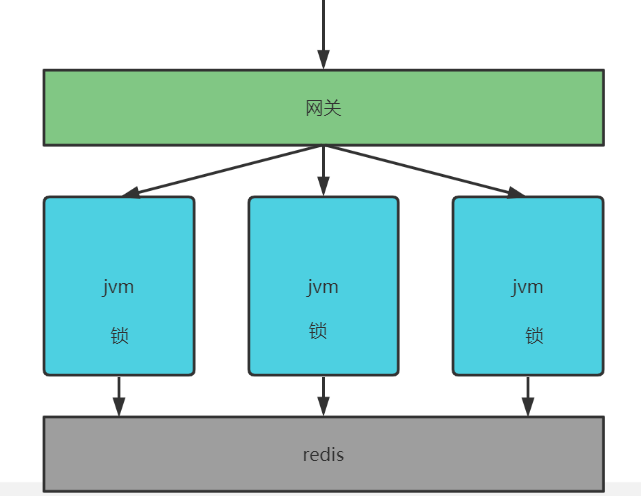

讲义先使用 `synchronized(this)`。若整个查询方法都进入同步区，即使缓存已命中也必须排队；一个Spring单例Service中的所有课程请求还会竞争同一把锁。

```java
// 反例：命中缓存的请求也被同一把锁串行化。
public CoursePublish queryWithGlobalLocalLock(Long courseId) {
    synchronized (this) {
        return getWithNegativeCache(courseId);
    }
}
```

这可以减少单JVM内的部分重复查询，但会伤害正常命中路径，并把不同courseId绑在一起。讲义的吞吐量下降用于说明锁范围的代价，不意味着所有synchronized都低效。

更关键的是本地锁仅对当前进程、相同锁对象的线程生效。content部署多个实例时，每个JVM都有自己的this，即使都使用synchronized，也可能各查一次数据库。


## 15. 二次检查：先走快路径，miss后再互斥

以下校正示例仍用单JVM的一把全局锁，目的是说明“锁外读 + 锁内二次读”。首次和二次读取都必须处理负缓存。

```java
public CoursePublish getWithLocalDoubleCheck(Long courseId) {
    String key = "course:" + courseId;
    String cached = stringRedisTemplate.opsForValue().get(key);
    if (cached != null) {
        return "null".equals(cached)
                ? null : JSON.parseObject(cached, CoursePublish.class);
    }

    synchronized (this) {
        String secondRead = stringRedisTemplate.opsForValue().get(key);
        if (secondRead != null) {
            return "null".equals(secondRead)
                    ? null : JSON.parseObject(secondRead, CoursePublish.class);
        }
        CoursePublish data = getCoursePublish(courseId);
        long ttlSeconds = data == null ? 30L
                : 300L + ThreadLocalRandom.current().nextInt(100);
        stringRedisTemplate.opsForValue().set(
                key, data == null ? "null" : JSON.toJSONString(data),
                ttlSeconds, TimeUnit.SECONDS);
        return data;
    }
}
```

线程A、B都在锁外发现miss；A获锁、回源并写入缓存；B随后获锁时若不二次读取，就仍会重复查库。二次检查解决的是“等待期间状态已经改变”。

讲义有一版在嵌套区域重复声明 `Object jsonObj`，与外层局部变量作用域重叠，Java不允许这样重复声明；这里用 `cached`、`secondRead`避免该问题。这段不是完整工程补丁，也未编译运行。


## 16. 本地按key锁：减少无关课程竞争，但仍有进程边界

把重建锁从“全部课程共用一把”改为“同一课程共享”，可以让不同课程并行回源。实现时要保证同一时刻同一key的竞争者确实拿到相同锁对象。

| 方案 | 优点 | 必须处理的问题 |
| --- | --- | --- |
| 固定数量分段锁 | 对象数量有界，管理简单 | 不同key可能落到同一分段，发生额外竞争 |
| ConcurrentMap维护锁 | 更接近每个key独立互斥 | 删除时的竞争、引用计数、生命周期与内存增长 |
| 本地single-flight | 同一key共享一个正在加载的结果 | 失败、超时、取消与对象清理 |

不要无限对courseId字符串调用intern，也不要让锁Map无限增长。若释放后立即移除锁，但仍有线程等待旧对象，新请求可能创建另一把锁，导致同一key同时有两组执行者。

多实例回源需要跨进程协调，通常采用Redis/Redisson等分布式锁；如果一次重复回源成本很小，也可以结合数据库容量接受少量重复，避免引入过多协调开销。选型应围绕业务负载与故障容忍度。


## 17. 分布式锁：同一课程的重建者共享一把锁

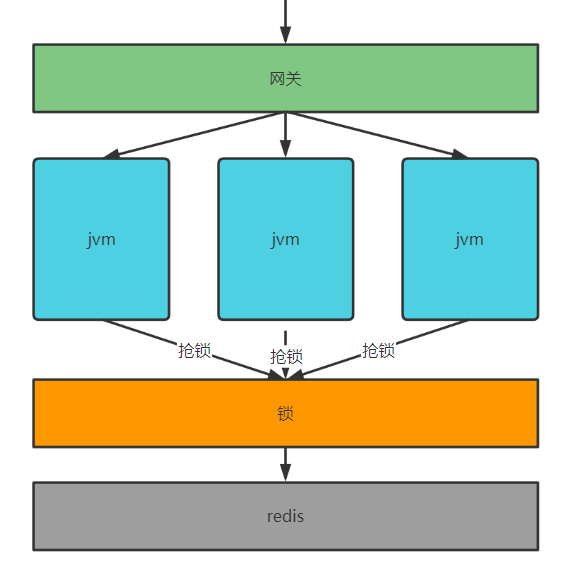

分布式锁把互斥状态放到各实例可共同访问的存储中。课程查询用 `coursequerylock:{courseId}`，数据缓存仍用 `course:{courseId}`；锁的value应描述持有者，不能存课程内容。

一个可用的锁至少需要考虑：互斥获取、获取与期限原子设置、唯一持有者、原子条件释放、获取超时、业务超时、持有者宕机后的自动失效、网络错误时的行为。可重入、公平性等能力由具体方案提供，不能默认SET NX就具备。

分布式锁不仅有Redis一种方案，也可使用数据库唯一约束/条件更新、ZooKeeper等协调服务。需要比较延迟、可靠性、故障恢复、业务操作能否受存储本身约束。

**锁和数据库事务是两种机制**。获得Redis锁并不让MySQL写入与Redis变成一个原子事务；锁过期或Redis故障转移后，旧线程可能继续工作。涉及资金和权益的写入还要依赖数据库条件、唯一键、版本或fencing约束。


## 18. SET NX：加锁与过期必须同时完成

Redis的SET可以同时设置不存在时才写入与过期时间：

```text
SET coursequerylock:100 RANDOM_OWNER_TOKEN NX PX 10000
```

NX表示key不存在才写入；PX的单位为毫秒，EX的单位为秒。不要先SETNX、后EXPIRE：若两步之间进程崩溃，锁可能没有期限，无法自动恢复。

Java获取示意：

```java
String lockKey = "coursequerylock:" + courseId;
String ownerToken = UUID.randomUUID().toString();
Boolean acquired = stringRedisTemplate.opsForValue()
        .setIfAbsent(lockKey, ownerToken, 10L, TimeUnit.SECONDS);
if (Boolean.TRUE.equals(acquired)) {
    // 执行有界的重建任务；最终按ownerToken原子释放。
}
```

每次获取生成新的随机token，不要让所有请求共用`001`。setIfAbsent的具体超时与序列化行为应按Spring Data Redis版本确认；示例不包含完整释放逻辑，不能照抄为生产锁工具。

获取失败应短暂等待、有界重读或快速失败，避免无间隔while循环消耗CPU和Redis请求。超时结果不明确时也不能假定“我肯定持有锁”并删掉key。


## 19. 条件释放与Lua：防止删掉别人的锁

事故时序：A获锁，执行慢于锁TTL；锁过期后B获锁；A结束时直接DEL，就会删除B的锁。唯一token加原子比较删除可以防止这种误释放。

```lua
if redis.call('get', KEYS[1]) == ARGV[1] then
    return redis.call('del', KEYS[1])
else
    return 0
end
```

调用示意：

```java
String scriptText =
        "if redis.call('get', KEYS[1]) == ARGV[1] then " +
        "return redis.call('del', KEYS[1]) else return 0 end";
DefaultRedisScript<Long> releaseScript =
        new DefaultRedisScript<>(scriptText, Long.class);
Long released = stringRedisTemplate.execute(
        releaseScript, Collections.singletonList(lockKey), ownerToken);
```

先GET判断、再单独DEL不是原子操作，两步之间仍可能换持有者。Lua让比较与删除在Redis执行期间不被其他命令交错。

**Lua原子执行不等于数据库式的错误回滚**：脚本运行时出错，之前已经执行的写操作不保证自动撤销。讲义“要么全部成功，要么全部失败”不能用于解释所有Lua脚本。

token保护解锁，不能阻止租约过期的A继续查库或写旧缓存。为限制旧持有者写入，需要版本校验、存储端条件更新或fencing等额外设计；在缓存重建中也应控制查询时长，并处理与发布更新的竞争。


## 20. Redisson接入：依赖、配置与资源生命周期

讲义选择Redisson，基于Netty提供分布式对象和同步工具，例如RLock、队列、计数器、Semaphore和布隆过滤器。它封装了获取、释放、续期等逻辑，减少手写锁协议的成本。

讲义使用的依赖版本是 **3.11.2**：

```xml
<dependency>
    <groupId>org.redisson</groupId>
    <artifactId>redisson-spring-boot-starter</artifactId>
    <version>3.11.2</version>
</dependency>
```

```yaml
# 课程旧版本配置示意：资源必须在服务实际运行classpath中。
spring:
  redis:
    redisson:
      config: classpath:singleServerConfig.yaml
```

配置不只是“拷贝进config工程”就必然生效，还需确认依赖引用、资源打包和最终启动服务的classpath。RedissonClient通常由容器统一管理，避免每次请求新建客户端和Netty线程。

**版本边界**：讲义对“Java1.6+、Redis2.8+”的描述属于当时资料，不能当成最新版支持范围。升级时核对JDK、Redis、Spring Boot、starter兼容关系、属性前缀和API行为，不能只替换version数字。

使用RedisTemplate与Redisson同时访问同一个Redis时，要对齐地址、逻辑库、key编码和value编码。讲义数据缓存与锁key分开，不能让两个客户端用不同codec读写同一个业务key后误判缓存。


## 21. 两份Redisson配置：字段含义与静态校正

| 配置 | 本次阅读到的重点 | 解释 |
| --- | --- | --- |
| singleServerConfig.yaml | database=0，connectTimeout=10000，timeout=3000 | 逻辑库、连接超时和命令响应超时；时间字段通常为毫秒 |
| singleServerConfig.yaml | retryAttempts=3，retryInterval=1500 | 重试次数与间隔；多层重试会增加总耗时 |
| singleServerConfig.yaml | connectionMinimumIdleSize=32，connectionPoolSize=64 | 普通连接池的最小空闲与上限 |
| singleServerConfig.yaml | subscriptionConnectionMinimumIdleSize=1，subscriptionConnectionPoolSize=50 | 订阅连接池，与普通连接池分开 |
| singleServerConfig.yaml | threads=8，nettyThreads=8 | 工作线程与Netty线程配置 |
| clusterServersConfig.yaml | 三个nodeAddresses，readMode=SLAVE，scanInterval=1000 | 集群发现地址、读取策略与拓扑扫描 |
| clusterServersConfig.yaml | threads=0，nettyThreads=0 | 使用所用Redisson版本的默认计算规则，不是没有线程 |
| 两份文件 | JsonJacksonCodec与NIO | 编解码与传输方式；原文件包含Java类型标签 |

单机配置中还有pingTimeout、failedAttempts、reconnectionTimeout等旧版本字段；新版是否支持，要以具体版本文档和配置解析为准。不要把单节点配置与集群配置同时叠加使用；Redis Cluster通常只用DB0。

**实际文件问题**：集群配置末尾是 `"transportMode":"NIO"`，缺少块映射中通常需要的冒号后空格。应校正为 `transportMode: NIO`，并用目标Redisson版本验证完整配置。本次仅静态检查，未启动客户端或连接Redis。

原文件还包含 `!<org.redisson.codec.JsonJacksonCodec>`、loadBalancer等类型标签。通用YAML safe loader不认识Java标签，不能据此直接断言Redisson解析失败；必须区分“普通YAML语法”与“客户端特定标签处理”。

不带Java标签的最小单机教学示例：

```yaml
singleServerConfig:
  address: redis://127.0.0.1:6379
  database: 0
  connectTimeout: 10000
  timeout: 3000
  retryAttempts: 3
  retryInterval: 1500
  connectionMinimumIdleSize: 8
  connectionPoolSize: 32
threads: 8
nettyThreads: 8
transportMode: NIO
```

这份示例使用默认codec，池大小仅供理解，不是对原配置的完整替换。真实连接地址、认证与TLS由环境配置提供，不把凭据写入笔记；连接池大小也需结合服务副本数和Redis连接上限评估。


## 22. RLock与Watchdog：等待时间和持锁期限不同

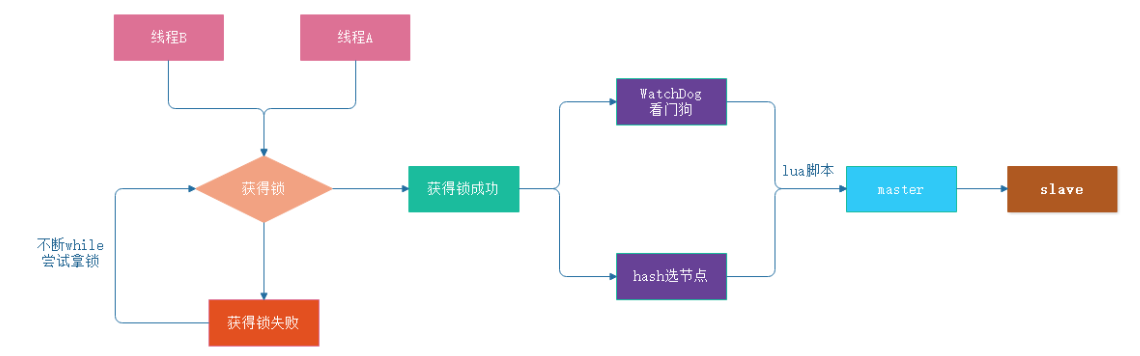

| 调用 | 获取行为 | 持锁期限/续期的常见行为 |
| --- | --- | --- |
| lock() | 持续等待直到取得锁 | 未指定leaseTime时通常使用Watchdog |
| lock(leaseTime, unit) | 等待取得锁 | 显式租约到期释放，通常不启用自动续期 |
| tryLock() | 立即尝试，返回true/false | 不显式指定租约，核对版本的续期规则 |
| tryLock(waitTime, unit) | 最多等待指定时间 | 不指定固定租约，通常可使用Watchdog |
| tryLock(waitTime, leaseTime, unit) | 最多等待waitTime | 获锁后租约为leaseTime，通常不自动续期 |
| unlock() | 当前持有线程释放锁 | 仅成功获锁的持有线程调用 |

waitTime决定“最多等多久”，leaseTime决定“拿到以后最多持有多久”；**没有waitTime必须大于leaseTime的通用要求**。讲义的该注释应校正。

常见默认Watchdog租约是30秒，客户端按约租约的三分之一周期续期，具体以配置与版本实现为准。续期通常从成功持锁后就被安排，不是先等过期再抢救；进程宕机、无法续期时锁会在剩余期限后失效。

Watchdog减少固定租约过短的问题，不能保证永久持锁。长时间GC、网络分区、Redis异常和故障转移仍需考虑。显式leaseTime时若业务超过期限，可能产生重叠执行；要给业务设置自己的超时和结果提交规则。

讲义用“失败一直while循环”概括竞争，实际客户端可能使用订阅通知、重试等机制，不能推断所有实现都纯忙等。公平锁、可重入、订阅和跨线程释放等细节也要按API约定使用，不要用forceUnlock作为普通finally释放。


## 23. 课程查询的Redisson校正示例

讲义最终版用每门课程一把RLock，先查缓存、再加锁、二次查缓存、查库、缓存一天、finally解锁。它说明跨实例控制回源的思路；下面进一步区分正负TTL、限制等待并处理线程中断。

**这是服务方法片段与辅助方法，不是已取得的day14工程代码**。假设已有stringRedisTemplate、redissonClient、JSON库、log和查询发布数据的getCoursePublish；所用RLock重载需要按实际Redisson版本核对。

```java
public CoursePublish getCoursePublishCache(Long courseId) {
    if (courseId == null || courseId <= 0) {
        throw new IllegalArgumentException("课程ID不合法");
    }
    String cacheKey = "course:" + courseId;
    String lockKey = "coursequerylock:" + courseId;
    String cached = stringRedisTemplate.opsForValue().get(cacheKey);
    if (cached != null) {
        return decodeCourse(cached);
    }

    RLock lock = redissonClient.getLock(lockKey);
    boolean acquired = false;
    try {
        // 200毫秒是获取等待预算；此重载没有显式固定leaseTime。
        acquired = lock.tryLock(200L, TimeUnit.MILLISECONDS);
        if (!acquired) {
            String afterWait = stringRedisTemplate.opsForValue().get(cacheKey);
            if (afterWait != null) {
                return decodeCourse(afterWait);
            }
            throw new IllegalStateException("课程信息重建中，请稍后重试");
        }

        String secondRead = stringRedisTemplate.opsForValue().get(cacheKey);
        if (secondRead != null) {
            return decodeCourse(secondRead);
        }

        CoursePublish data = getCoursePublish(courseId);
        long ttlSeconds = data == null ? 30L
                : 300L + ThreadLocalRandom.current().nextInt(100);
        String payload = data == null ? "null" : JSON.toJSONString(data);
        stringRedisTemplate.opsForValue().set(
                cacheKey, payload, ttlSeconds, TimeUnit.SECONDS);
        return data;
    } catch (InterruptedException e) {
        Thread.currentThread().interrupt();
        throw new IllegalStateException("等待课程重建被中断", e);
    } finally {
        if (acquired) {
            releaseCourseLock(lock, lockKey);
        }
    }
}

private CoursePublish decodeCourse(String cached) {
    return "null".equals(cached)
            ? null : JSON.parseObject(cached, CoursePublish.class);
}

private void releaseCourseLock(RLock lock, String lockKey) {
    try {
        if (lock.isHeldByCurrentThread()) {
            lock.unlock();
        }
    } catch (RuntimeException e) {
        // 不用forceUnlock；记录异常，依赖剩余租约回收。
        log.warn("释放课程重建锁失败: {}", lockKey, e);
    }
}
```

关键点：正常命中不加锁；等待后和获锁后都重新检查；负缓存在全部命中分支一致处理；只在成功获取后尝试释放；中断恢复标志；查询失败不写“课程不存在”。释放异常不覆盖主要结果或查询异常，但要被监控。

该示例采用明确失败策略：Redis/锁不可用时异常交给统一边界转为暂不可用，避免所有请求无界直查数据库。若业务需要降级查库，应另外实现限流、并发许可和超时，并区分数据库失败与无记录。

200毫秒不是固定推荐值，应由整体响应预算决定。代码还没有实现版本化回填、全局回源限额、热点预热和发布失效补偿，不能据此声称强一致或“永远只查库一次”。


## 24. 缓存一致性：发布、下架与回填要一起设计

锁只串行化竞争重建的读者，不能自动协调发布更新。典型竞争如下：

```text
读者A：miss → 查到旧版本v1 → 暂停
发布B：数据库提交新版本v2 → 删除course缓存
读者A：恢复 → 把v1写回Redis
后续请求：命中旧v1，直到失效或补偿
```

“先更新数据库，再删除缓存”是常见起点，但仍有旧值回填窗口。可以结合发布版本、短TTL、更新通知、延迟再次失效或周期对账等方案；版本校验与写入之间若仍有竞态，需让协议本身具备条件更新/统一协调能力，不能只读一次版本就宣称解决。

可靠发布流程通常在数据库事务提交后再处理缓存与索引。若提交后通知失败，使用本地消息表/Outbox保存待同步任务，重试并记录完成阶段。删除缓存是幂等操作；发布事件需携带courseId和版本，避免旧事件覆盖新数据。

下架也要同步Redis、搜索索引、静态页面或访问入口。若必须立即禁止公开访问，仅靠7天TTL或“最终会过期”不够，需要明确状态检查、失效保障和可接受窗口。已有学生权益是否保留是业务规则，应与公开销售状态区分。

逻辑过期允许的陈旧数据、支付/权益的严格判断、后台编辑的实时要求不同。设计一致性时说明“哪个数据允许旧多久、失败时展示什么、如何补偿”，比笼统承诺全部强一致更有用。


## 25. 项目定位：B2B2C在线教育与三端职责

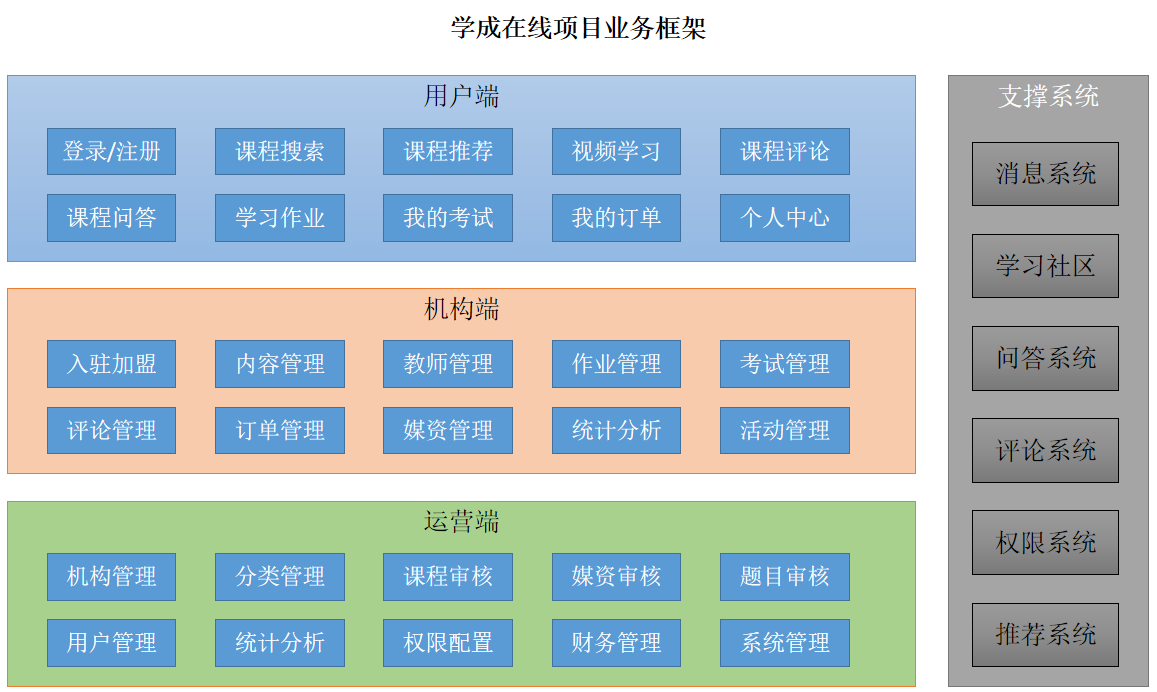

学成在线是B2B2C在线教育平台：平台连接教学机构与学生，机构提供课程，学生搜索、选课和学习，平台运营负责审核与管理。

| 角色/模块 | 主要能力 | 关键边界 |
| --- | --- | --- |
| 教学机构 | 编辑课程、课程计划、上传媒资、申请审核和发布 | 只能操作归属机构的数据 |
| 学生 | 门户搜索、课程详情、免费/收费选课、支付、课表和学习 | 以当前用户身份和有效权益访问 |
| 平台运营 | 课程审核、平台规则、运营管理 | 角色权限与审计 |
| 内容管理 | 草稿、审核、发布快照、静态化任务 | 草稿与公开发布数据分离 |
| 媒资管理 | 上传、分块合并、文件记录、异步转码、播放地址 | 文件归属、资源绑定与处理状态 |
| 搜索服务 | 索引公开课程、条件筛选、分页、高亮 | 来源于发布数据，保持同步 |
| 学习中心 | 选课、课表、有效期与播放资格 | 权益与课程章节关联 |
| 订单/支付 | 订单、支付交易、资金确认与结果消息 | 幂等、校验和权益补偿 |
| 认证授权 | 用户认证、令牌、服务权限和数据归属 | 身份可信且授权在后端生效 |

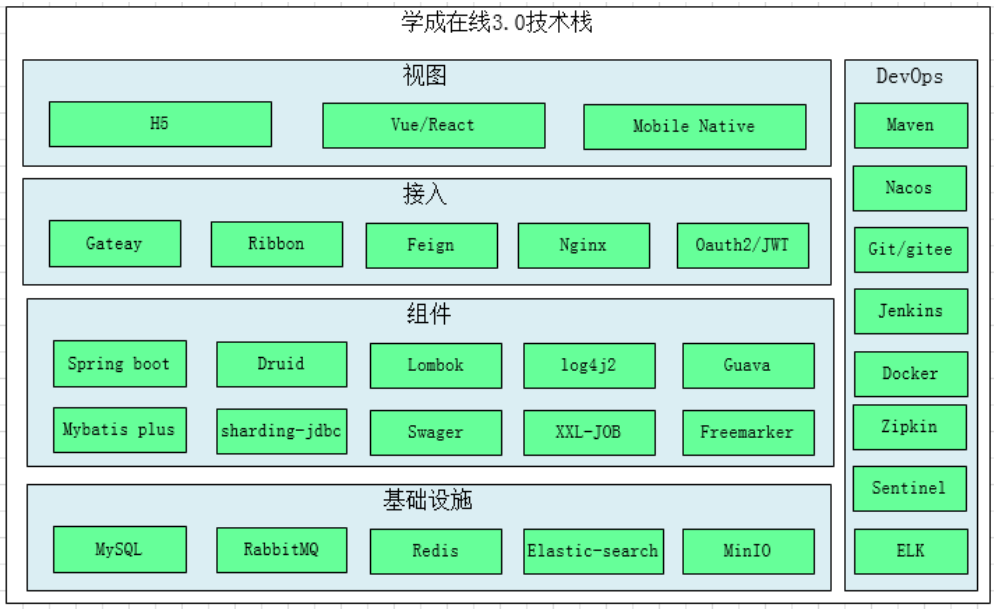

技术栈图还列有Sharding-JDBC、Zipkin、Sentinel等。它表达总体技术选择和扩展方向；不能仅凭图宣称课件工程已经完整实现、部署或自己完成了所有能力。

项目不是把中间件名称堆起来，重点是它们解决的具体问题：Redis减少重复读取，RabbitMQ解耦结果通知，XXL-JOB处理可重试任务，Elasticsearch支持搜索，MinIO存储文件，Nacos维护服务与配置，Gateway提供统一入口。


## 26. 工程分层与调用链：Nacos、Gateway和服务职责

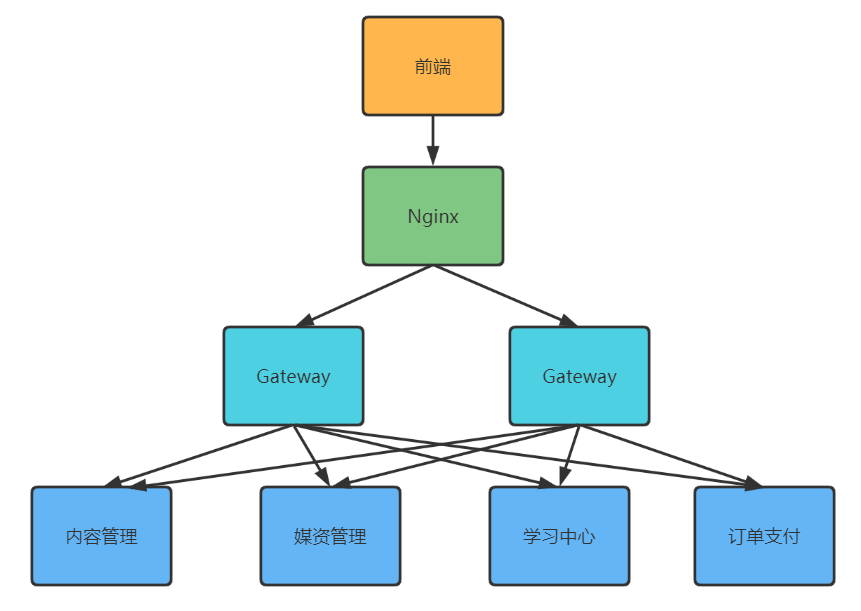

课程工程常按 `api → service → mapper`组织：api提供Controller和接口文档，service承担业务规则与事务，model承载Entity/DTO，Mapper访问数据库。parent维护版本与构建，base提供公共响应、异常、模型和消息相关能力。

依赖方向应避免循环，也不把一切业务塞进公共base。Feign接口是跨服务契约，不能通过直接依赖其他服务的内部实现类代替远程边界。

| 组件 | 项目中的作用 | 配置核对点 |
| --- | --- | --- |
| Nacos发现 | 实例注册、按服务名找到服务 | 实际spring.application.name、namespace、健康实例 |
| Nacos配置 | 管理环境配置、公共与业务配置 | namespace、group、dataId、profile、刷新规则 |
| Gateway | 按路径把请求路由到目标服务 | path谓词、服务名、前缀处理、过滤器顺序 |
| Nginx | 静态页面与API/文件代理 | 站点目录、URI转发、同源入口 |
| Feign | 服务间HTTP调用与契约封装 | 超时、错误映射、重试与降级 |

总结文档中有 `content-service-dev.yaml` 的命名例子，但应用名片段也出现content-api。真实dataId要与当前应用名、profile、扩展名和显式配置匹配，不能只照示例名字创建文件。

网关校验身份是第一道边界，服务还要做操作权限和数据归属检查。仅检查Authorization非空不算验证JWT；也不能任由请求伪造用户头后绕过服务校验。

跨服务链路要传递关联ID并记录必要耗时。统一入口不能消除服务间失败，远程调用预算需要放入整体响应目标中。


## 27. 接口、联调与失败策略：浏览器同源不等于后端授权

接口开发从输入、返回、权限、错误和幂等约定开始。DTO接收请求，参数校验处理格式/范围；Service检查存在性、状态和归属，事务覆盖本地业务修改；统一异常把错误转成可理解响应。

HTTP错误与业务错误需一致约定，不能让所有失败都返回200却不说明业务状态。分页、排序、默认值和空集合也需要在接口文档中明确，联调时与前端mock逐项比对。

**跨域校正**：浏览器按协议、域名、端口判断origin。Nginx同源代理应让页面向自己origin的 `/api/...` 发请求，再由Nginx转发后端；“两个都是IP地址”并不代表同源。

```text
页面：https://portal.example.test/course.html
页面请求：https://portal.example.test/api/content/...
Nginx服务端转发：内容服务/网关内部地址
```

直接跨origin时，按可信来源配置CORS，并处理OPTIONS预检。带凭据请求不能简单配置Access-Control-Allow-Origin为`*`；CORS限制浏览器访问响应，不代替身份认证、权限或CSRF设计。JSONP只适用于有限脚本加载场景，不适合作为认证API的通用跨域方案。

失败策略要区分：超时限制等待；隔离限制资源占用；熔断暂时停止调用高故障依赖；降级提供明确的替代响应；限流控制入口/回源数量。Feign fallbackFactory能否生效与版本、依赖和配置有关，不能只加类就认定已开启。

公开详情可以提示暂不可用或允许窗口内的旧数据；支付和收费播放校验失败不能被降级成“支付成功”“拥有权益”。多个调用层同时重试还可能放大请求，应统一预算并检查幂等。


## 28. 内容审核与发布：本地事务 + 可补偿同步

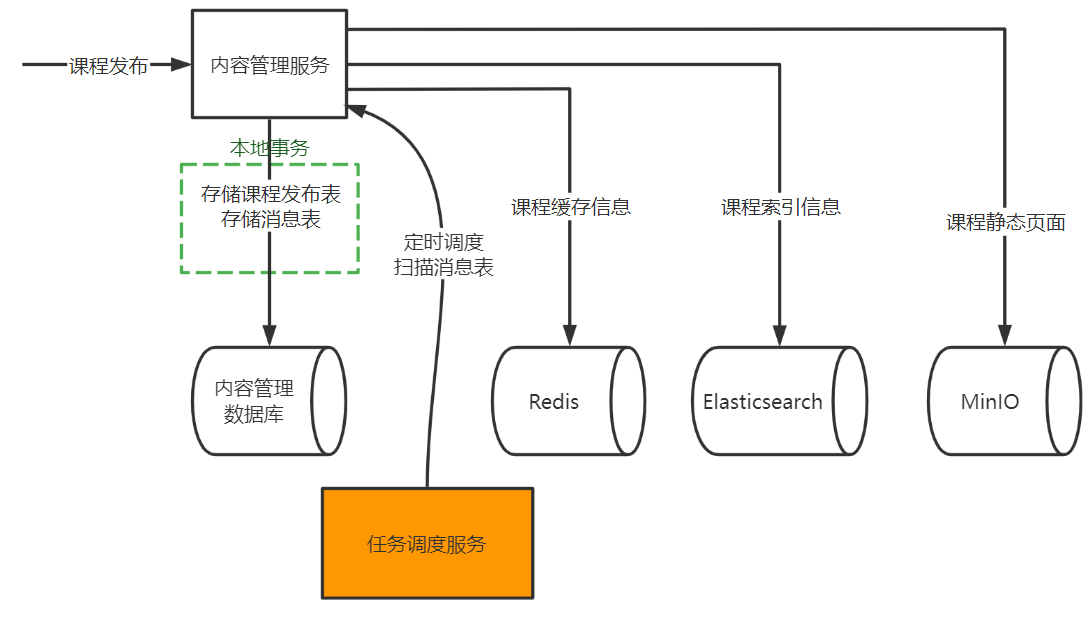

课程生命周期可概括为：编辑课程与计划 → 提交审核 → 审核通过 → 发布。实际状态码、允许转换和机构归属按接口规则校验，不能跳过审核直接凭courseId发布其他机构课程。

发布时生成CoursePublish快照，把课程基本信息、营销信息与计划树组织成公开读取模型。快照与编辑表分离，使草稿改动不会立即改变上线内容。

```text
内容服务本地数据库事务
  → 校验归属/状态
  → 保存或更新发布快照与发布状态
  → 写入待处理消息记录
事务提交后
  → 任务领取消息
  → 页面静态化并存储到MinIO
  → 同步Elasticsearch
  → 更新或失效Redis
  → 记录每个阶段、失败原因与完成状态
```

本地消息表/Outbox将“发布事实”和“后续同步意图”放入同一数据库事务，避免只改数据库却丢失同步任务。它不让Redis、ES和MinIO自动进入MySQL事务；靠可重试任务实现最终一致。

课程发布任务要保存版本并做幂等，同一消息重复执行不能重复制造错误记录。部分成功后应从失败阶段补偿；旧版本任务延迟到达时不能覆盖新版本。

“最终一致”需要完成时限、重试上限、告警、人工修复或对账。不能把CAP中的AP简化成“所有操作都不用一致性”，本地审核/发布状态转换仍需严格校验。


## 29. 静态化与课程搜索：两个发布投影的不同用途

Freemarker把发布模型填入模板生成课程详情HTML，存入对象存储，再由页面入口访问。静态化减少反复渲染与数据库读取，但更新、下架、模板版本和资源路径仍要管理；不是把任何网页保存下来就完成业务发布。

Elasticsearch对公开课程构建搜索索引，解决全文检索、过滤、聚合和高亮。索引字段按用途设计，不能把MySQL全部列无差别复制到索引。

| ES设计 | 用途/注意 |
| --- | --- |
| text + 分词器 | 课程名/描述等全文匹配；IK需与部署版本兼容 |
| keyword | 精确筛选、排序、聚合，如课程分类/机构标识 |
| bool/must | 组织相关性查询条件 |
| bool/filter | 分类、价格、状态等不需要相关性评分的条件 |
| highlight | 展示匹配词；前端处理标记与输出安全 |
| aggregation | 分类等统计；与当前筛选条件的口径匹配 |
| 分页与排序 | 明确默认顺序，避免大量深分页开销 |

索引同步来自发布数据，下架应删除/更新可见状态。ES索引可重新构建，发布事实与恢复来源仍在数据库；搜索结果短暂陈旧时，详情和后续选课应再次按业务状态判断。

讲义索引副本0适合课堂单节点，不代表高可用方案。`scaled_float`配合100可用于搜索价格索引，但真实支付金额仍以数据库业务金额和BigDecimal/最小货币单位核对，不能把搜索字段作为资金事实。


## 30. 媒资上传与断点续传：校验完整性，也要校验归属

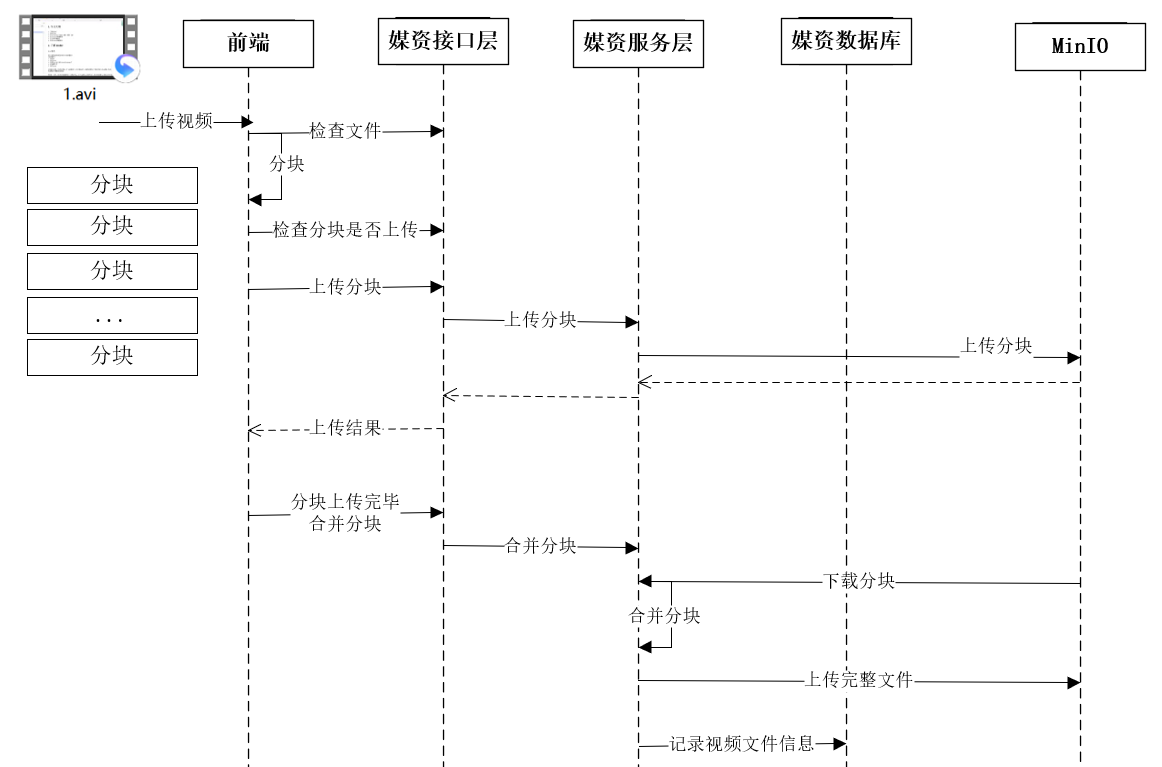

小文件可整体上传，大视频通常分块：客户端计算标识并切片，服务端按块存储；中断后检查已有块，继续上传缺失块；全部齐全后合并、校验并保存媒资记录。

```text
上传前检查 → 文件已存在则按规则复用
  → 检查分块 → 上传缺失块
  → 请求合并 → 校验块数量、顺序、大小与权限
  → 合并后核对完整文件标识与大小
  → 写入对象存储与媒资记录
  → 必要时进入视频处理任务
```

MD5可作为课件中的文件标识和完整性校验，不能代替授权或抗恶意碰撞的安全保证。服务端不能只信客户端提交的MD5、块数和路径；要检查用户/机构、上传任务、块索引范围、实际大小和最终结果。

重复上传/合并要幂等，部分失败允许重试；临时块和失败文件要有清理策略。多个用户上传相同内容时，“物理对象去重”不等于“所有用户可以共享读写权限”。

MinIO负责对象存储，数据库负责媒资业务记录，两者之间仍可能部分成功，需要补偿与对账。生成播放地址时还要结合章节绑定、文件处理状态与访问策略，不能仅因对象存在就对任何人返回。


## 31. 视频处理与XXL-JOB：调度分工不等于恰好执行一次

视频上传后，格式或编码可能不适合浏览器直接播放。课程通过异步任务调用FFmpeg等工具处理，成功后更新对象地址、处理状态和任务历史；失败记录原因并按规则重试。

数据库任务表让待处理任务可追踪。处理程序领取任务后，下载源文件、执行有时限的转码、检查输出、上传结果、更新业务记录；finally清理临时资源。不能在上传HTTP请求里无限等待长时间转码。

XXL-JOB提供调度与分片信息，例如按 `任务ID % 分片总数 == 分片序号` 分工。它分配“哪组任务由谁处理”，**不保证任务恰好执行一次**。

| 风险 | 应对设计 |
| --- | --- |
| 上轮未完成，下轮再次触发 | 合适的调度阻塞策略 + 数据库条件领取 |
| 多个执行器拿到相同任务 | 状态/版本条件更新，成功领取者继续 |
| 领取后执行器宕机 | 任务租约、超时回收与可重试状态 |
| 转码成功但上传/数据库更新失败 | 可识别输出、幂等存储、补偿与对账 |
| 旧任务晚完成覆盖新结果 | 任务版本和条件提交 |

调度器的“忽略/丢弃重复触发”只影响某种触发行为，不能代替数据库领取协议。锁也不能让外部进程执行和MySQL更新成为原子操作；业务处理应按“允许重试、结果幂等”设计。

视频转码任务与课程发布同步任务都是后台工作，但职责不同。RabbitMQ更适合结果事件与异步通知，XXL-JOB适合定期扫描和补偿；课程可以组合两者，不需要把所有任务都改成同一种中间件。


## 32. 统一认证、JWT与微信扫码：身份链路的几个层次

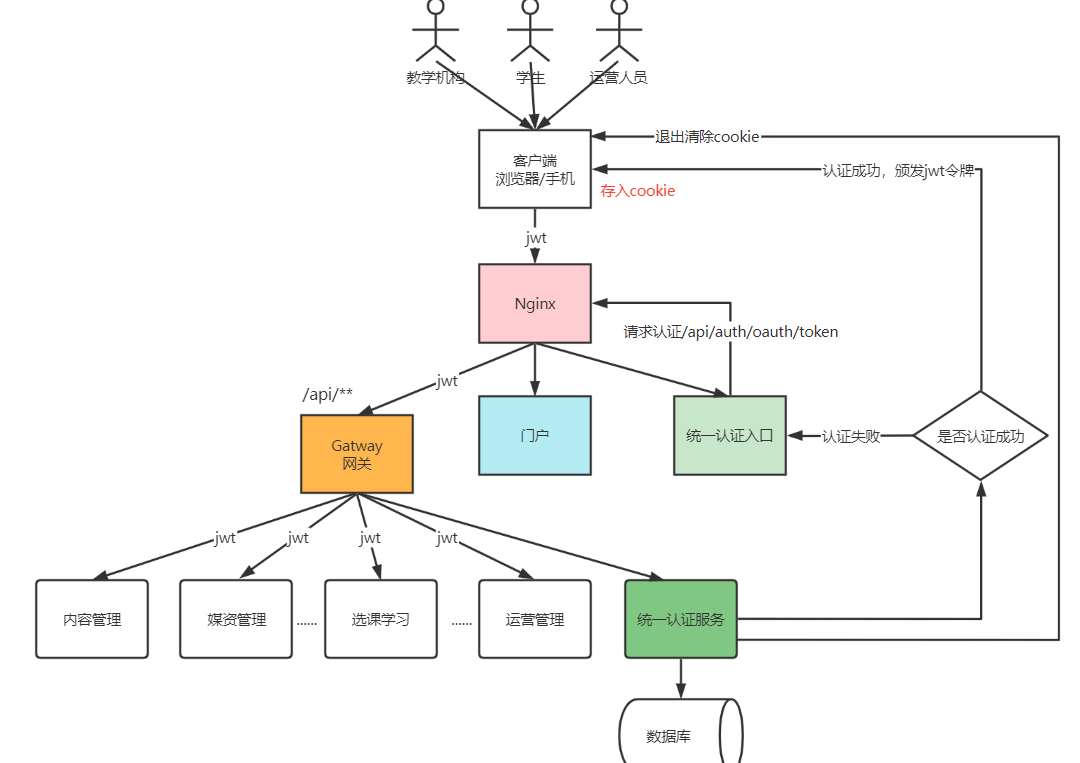

典型链路：用户向认证服务提交登录信息 → 认证通过后取得本系统访问令牌 → 请求携带令牌 → 网关/资源服务验证 → 业务服务检查权限与归属。

OAuth2主要描述授权：资源所有者、客户端、授权服务器、资源服务器；不能笼统等同于全部身份协议。微信扫码登录结合外部授权与用户资料建立本系统身份：

```text
前端取得授权地址并展示二维码
  → 用户在微信完成授权
  → 回调接收临时code与state
  → 后端核验state并向微信交换access_token
  → 使用外部token获取授权范围内的用户标识/资料
  → 绑定或创建本系统账号，处理账号冲突
  → 通过本系统认证流程签发本系统JWT
```

外部access_token与本系统JWT用途不同，不能混着验证或把外部令牌直接当作内部登录凭据。state应与当前流程关联、校验并单次消费，回调地址与账号绑定也需符合授权范围。

常见签名JWT（JWS）结构是 `Base64URL(header).Base64URL(payload).signature`。Base64URL是编码，**签名不是加密，payload可被读取**；不要放密码或私密资料。JWT并不天然保证用户当前仍有所有旧权限。

| 算法/校验 | 正确理解 |
| --- | --- |
| HS256 | HMAC-SHA256，签发与验证依赖共享秘密 |
| RS256 | RSA签名，私钥签发、公钥验证 |
| 算法白名单 | 接受预期算法，拒绝意外算法或无签名令牌 |
| claims | 核验exp、iss、aud及系统约定的身份/时间字段 |
| 生命周期 | 短有效期、刷新策略、密钥轮换、注销/撤销与权限变更 |

总结讲义把签名、加密、MD5/SHA等表述混在一起，应按上述区分。验证不只是解析JSON或检查令牌非空，还要验证签名与claims；权限变更和账号禁用需有生效策略。


## 33. Spring Security、RBAC与验证码：认证之后仍需授权

Spring Security常见认证路径是Filter接收请求 → AuthenticationManager → AuthenticationProvider → 查询用户并验证凭据 → 把Authentication放入SecurityContext。普通表单登录与OAuth令牌端点不一定经过完全相同的Filter，不能套用一张图解释所有入口。

资源请求随后根据认证状态与权限做控制。课程中的 `@PreAuthorize` 等方法级授权要配合开启相应配置；用户登录成功并不等于可以编辑课程、审核课程或操作其他机构资源。

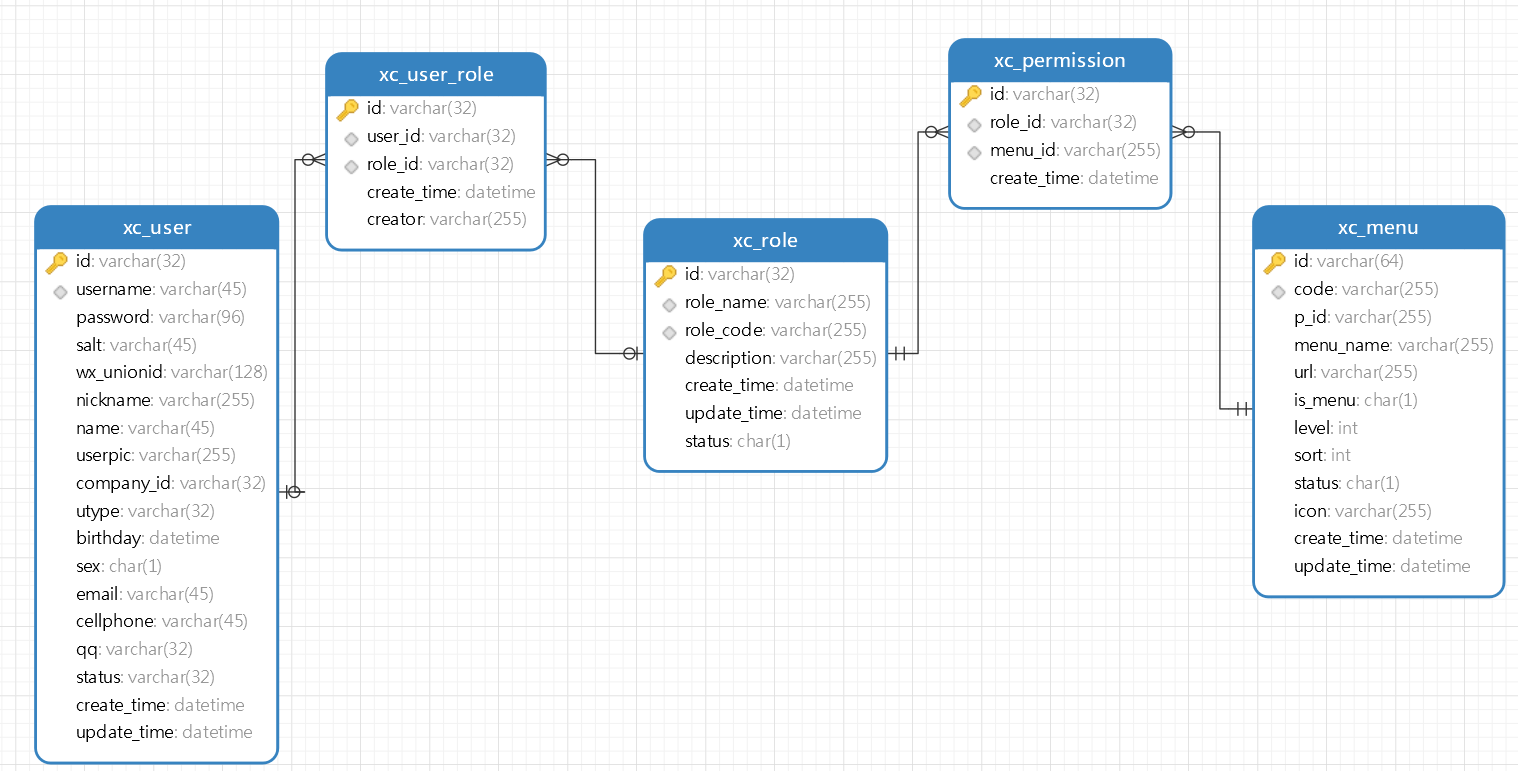

| 表/关系 | 作用 |
| --- | --- |
| xc_user | 本系统用户身份 |
| xc_role | 角色定义 |
| xc_user_role | 用户与角色的关联 |
| xc_menu | 菜单/功能资源信息 |
| xc_permission | 权限关联与课程中的权限查询模型 |

具体字段和连接关系以配套SQL为准。授予菜单可见性不能替代接口授权；接口权限还不能替代机构/用户归属校验。一个有“编辑课程”权限的人，只能编辑其有权管理的课程。

密码以适当的密码哈希机制存储与验证，不能明文比较或用普通MD5代替密码哈希。权限可放入令牌或缓存，但要说明撤销、角色变化与过期策略。

验证码链路：生成随机key与图片 → 服务端按key短期保存答案 → 页面只获得key和图像 → 用户提交key与答案 → 校验并消费。验证码接口不能把正确答案直接返回前端；还要控制获取/尝试频率、TTL和重复使用。

总结文档列出验证码30秒；是否真正开启应按运行配置和实际调用检查，不能仅凭总结描述认定所有登录入口已启用。前篇对照的day12基线曾有密码登录验证码调用被注释，这也不能反推本次未取得的day14源码状态。


## 34. 选课与学习：权益记录和播放校验各有职责

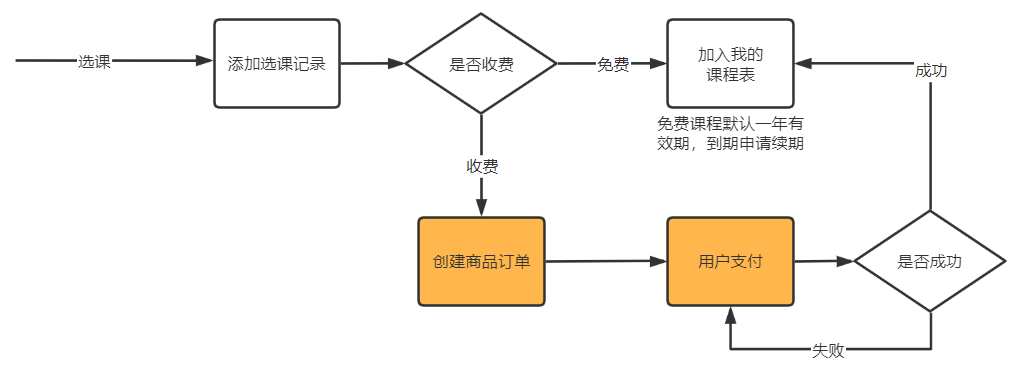

免费课程按规则直接建立选课/课表；收费课程先建立选课与订单，资金确认后由消息或补偿把选课转换为有效学习权益。讲义提到免费课程按一年续期，这是业务设计，需要与实际接口和数据验证区分。

```text
免费：选择课程 → 校验发布与免费规则 → 幂等建立课表
收费：选择课程 → 待支付选课/订单 → 支付确认 → 消息 → 有效课表
学习：当前用户 + 当前章节 + 媒资绑定 + 有效课表/试学规则 → 播放资格
```

课表可用用户ID+课程ID唯一约束避免重复插入，重复通知应返回已处理结果而非再次创建。权益有效期、退款、课程下架和已有购买关系需要明确产品规则，不能只有一个“支付成功”的布尔值。

学习中心在获取播放地址时核对课程、章节、媒资归属，以及试学标记、用户身份、有效课表和期限。试学允许的是指定章节，不是前端把courseId/mediaId随意组合后都能访问。

服务端失败必须return/抛出对应错误后停止流程。第13篇已指出讲义有一处只调用validfail却没有return；如果继续执行，可能泄露播放地址。微服务调用失败也不能降级成拥有收费权益。

页面展示“继续学习”、返回视频URL和实际文件访问是三层：前端控制只是体验，后端判断才是资格；若视频本身公开且URL可长期复用，还需按产品需求设计访问入口、短期URL或防盗链等策略。


## 35. 订单、资金确认与RabbitMQ：支付成功后还有权益处理

项目需要区分三个结果：**支付平台确认资金 → 本系统订单/支付记录成功 → 学习中心权益生效**。它们不必在同一个瞬间完成，也不是单靠一个本地事务就能覆盖。

讲义主实现是支付宝沙箱支付。部分总结图提到微信支付，不能据此宣称已经完成并实测微信支付接入。

```text
学生发起选课 → 创建订单与支付交易 → 生成支付入口
  → 第三方支付平台处理
  → 异步回调或主动查询确认资金
  → 验签，核对金额/应用/收款方/交易号与订单
  → 本地事务更新支付记录和订单，写待发送事件
  → 事务后发送支付结果消息
  → 学习中心幂等处理，建立/更新课表
  → 消息确认与补偿对账
```

重复回调、查询与消息重投是正常情况。状态转换使用数据库条件更新/唯一键防止重复处理，订单/支付状态码如600/601要结合具体字段和语义读取，不能让相同数字在不同表中含混使用。

前端跳转成功页面不能作为资金确认。收到通知要核验签名、商户应用、收款方、金额、第三方交易号和本系统订单对应关系；数据库保存可信结果后再回复支付平台约定的响应。

**总结讲义的查询方向有误**：订单未收到支付结果，应向第三方支付平台查询资金状态；学习中心用于查询/补偿学习权益，不能代替支付平台回答是否到账。

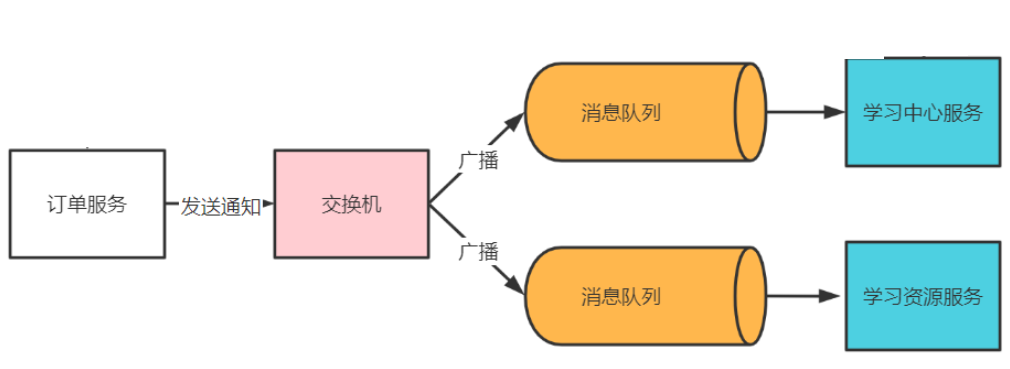

Fanout把消息复制到绑定队列。不同订阅服务要各自独立队列，才能各获得一份事件；多个消费者共用同一队列是竞争消费，通常由其中一个处理，不能称“每个消费者都收到”。

Publisher Confirm确认消息到达Broker，不代表学习中心事务完成；消费者ACK应在本地权益事务成功后发出。事务后发送失败仍需Outbox/重试；消费者处理完成但ACK丢失会重投，所以课表幂等不能省略。

资金到账但课表未建立时显示“权益确认中”，定位事件发送/消费/本地事务并补偿，避免用户重复支付。分布式锁不能代替这套资金校验、业务状态和消息幂等。


## 36. 研发、测试与部署：把问题变成可追踪的闭环

讲义的研发过程包括需求分析、设计、接口定义、开发、自测、联调、测试、修复、验收与上线运维。技术方案要能说明业务规则、依赖与失败恢复，接口契约先对齐有助于前后端并行。

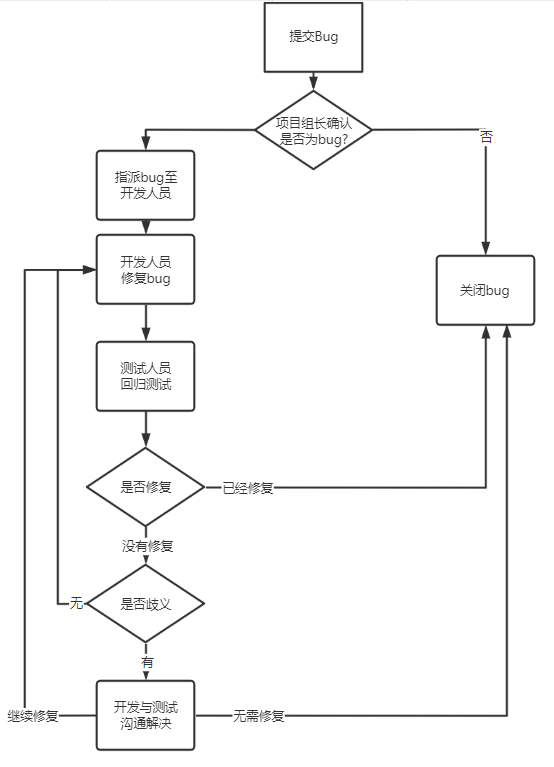

一个有效缺陷记录包括环境与版本、前置数据、复现步骤、期望/实际结果、必要日志和影响范围。修复后先验证直接问题，再回归受影响流程；测试通过并按流程验收后关闭，不能仅凭开发者说“改了”就结束。

| 验证层次 | 项目例子 |
| --- | --- |
| Service/数据库规则 | 非法状态转换、机构归属、重复课表、订单幂等 |
| 集成 | 发布任务写ES/MinIO/Redis、支付消息建立权益 |
| 接口与联调 | DTO/分页/错误契约、CORS、令牌与权限 |
| 端到端 | 编辑→审核→发布→搜索→选课→支付→学习 |
| 性能/恢复 | 冷缓存、热点过期、消息重投、依赖超时、任务宕机 |

部署与CI/CD详见第13篇：源码版本 → 构建 → 镜像/发布物 → 环境配置 → 启动 → 健康检查 → 验收与回滚。Jenkins/Gogs/Docker是工具，成功构建不等于业务发布成功。

运行后监控入口延迟与错误、连接池、Redis命中与锁等待、后台任务积压、消息重试、发布版本差异和权益补偿。恢复后复盘触发条件、检测缺口和改进措施，不把“重启恢复”当作根因结论。


## 37. 第14天实践与排错清单：本篇提供方案，未执行实验

以下用于之后在隔离环境中的功能与故障验证。本次只做资料阅读、文件生成和静态检查，**没有执行这些服务实验**。

| 场景 | 应检查的结果 | 排错入口 |
| --- | --- | --- |
| 连续读同一有效课程 | 结果正确，热缓存减少回源 | 命中率、数据库调用次数、响应内容 |
| 读不存在课程 | 短负缓存生效，返回不存在 | payload、TTL、ID校验 |
| 负缓存后课程发布 | 新发布数据在目标时限可见 | 发布失效、旧事件、补偿 |
| 单热点过期并发 | 回源受控，锁等待有界 | course锁key、二次检查、慢SQL |
| 多个服务实例同一热点 | 使用同一Redis/锁key，不各自无界回源 | 客户端地址/DB、codec、实例日志 |
| 不同课程同时miss | 可合理并行，总回源仍有上限 | 锁粒度、数据库连接池 |
| 数据库超时 | 不写“课程不存在” | 异常映射、超时预算 |
| Redis/锁服务不可用 | 明确失败或受限降级 | 熔断、回源许可、错误率 |
| 等锁线程中断 | 中断传播，未获锁不释放 | acquired标志、finally |
| 持锁服务崩溃 | 租约后可恢复，业务结果可重试 | TTL、任务版本、幂等记录 |
| 发布与旧读回填交错 | 旧版本不会长期覆盖新版本 | 版本协议、失效事件、对账 |
| 下架课程 | 搜索、详情、静态入口按规则收敛 | 发布状态、缓存、索引与页面 |
| 重复支付结果 | 一次有效状态转换，不重复权益 | 条件更新、Outbox、课表唯一约束 |
| 缺少/伪造用户身份 | 无越权数据或收费播放放行 | JWT验证、方法权限、归属规则 |

多实例测试要记录每个实例的回源统计，不能仅凭一个控制台没有打印SQL就断言只查了一次。缓存重建锁过期、缓存写失败、任务取消等情况下允许再次重建，应验证总负载与正确性。

出现吞吐下降时，先确认入口、版本、日志、线程与命中率一致，再看CPU/GC、网络、数据库与Redis。不要为了让数字好看而取消业务断言或跳过授权。


## 38. 讲义易错表述与本篇校正对照

| 讲义或常见读法 | 本篇校正 |
| --- | --- |
| 内部一次调用，QPS一定等于2TPS | 按入口/内部调用和业务事务定义统计口径 |
| 200线程代表200TPS或一万在线用户 | 线程、速率、耗时和用户行为不同，需要负载模型 |
| 负缓存注释300秒 | 对应调用实际是30秒 |
| Redisson最终示例所有结果缓存一天 | 正负TTL分开，负缓存过长影响新发布可见性 |
| 一把synchronized解决多实例问题 | 只约束相同JVM中的相同锁对象 |
| 嵌套作用域再次声明jsonObj | 使用不同局部变量名，避免Java声明冲突 |
| SETNX后再EXPIRE即可 | NX与过期一次原子设置，避免无期限锁 |
| 所有持有者用001，直接DEL | 每次唯一token，Lua比较token再删除 |
| Lua运行错误会撤销全部写入 | 原子执行是命令不交错，不保证运行时错误回滚 |
| waitTime必须大于leaseTime | 等待预算与持有租约是不同参数 |
| Watchdog等锁已过期后再续期 | 持锁后定时续期，续期失败仍会过期 |
| 集群配置末尾引号写法照抄 | 使用`transportMode: NIO`并按客户端版本验证 |
| 分片/锁确保任务恰好一次 | 领取协议、租约恢复和业务幂等仍必需 |
| JWT签名加密了payload | 普通JWS可读取payload，签名保护完整性 |
| 没收到支付结果就向学习中心查钱 | 订单查询第三方支付平台；学习中心处理权益 |
| 同队列的所有消费者都收到Fanout消息 | 队列之间各一份，同一队列内部竞争 |
| 技术栈图列了就表示个人已经完成 | 只按实际实现和验证证据描述成果 |

源码下载范围也属于必须说明的事实：本次day14完整包未取得，正文方法是讲义整理或校正示例。旧版本源码、前篇笔记和本日讲义不能互相冒充同一份最终实现。


## 39. 复习问答：用因果解释技术选择

**1．为什么课程详情适合缓存？** 公开发布后读多写少，相同courseId重复查询多，且发布快照可从数据库重建。要配合失效与版本规则，不能缓存任意草稿就直接公开。

**2．穿透、雪崩、击穿怎么区分？** 不存在数据持续回源是穿透；大批失效或Redis不可用引发集中回源是雪崩；单热点过期后的集中回源是击穿。分别观察数据存在性、key范围与缓存服务状态。

**3．为什么等到锁后再查缓存？** 等待期间另一个请求可能已重建。二次检查避免等待者继续重复查库，正缓存和负缓存都要检查。

**4．为什么锁要按courseId？** 同一课程的重建需要互斥，不同课程可以并行。全局锁让无关数据互相阻塞，但按key锁也不替代全局回源容量限制。

**5．为什么本地锁不够？** 多实例有不同JVM/锁对象。共享Redis锁才能跨实例协调，仍要面对租约、网络和存储故障。

**6．为什么需要唯一token和Lua？** token区分每次持有者，Lua让比较与删除不被其他命令交错，防止过期旧持有者删除新锁。它们不能禁止旧线程继续执行业务。

**7．Watchdog保证锁不会丢吗？** 不能。它在客户端可续期时延长租约；进程宕机、长停顿和网络故障可能导致失效。关键结果仍需数据库版本/条件和幂等。

**8．缓存更新只删除key够吗？** 常见起点，但旧读者可能在删除之后回填旧值。需明确版本、通知、TTL和补偿窗口，重要状态不能只等自然过期。

**9．XXL-JOB和RabbitMQ分别解决什么？** 前者调度与分片执行任务，后者分发异步事件。二者都不自动消除重复和部分失败，业务仍需领取、幂等与补偿。

**10．JWT验证通过后为什么还检查归属？** 令牌证明身份/声明，操作权限和数据范围是业务授权。某机构老师即使有编辑权限，也不能编辑其他机构课程。

**11．支付平台成功，为什么页面还不能马上学习？** 订单确认与课表权益之间有异步链路。需要验证消息和权益处理，展示确认中并补偿；不能要求重复付款或信任前端成功页面。

**12．如何证明优化有效？** 在可比条件下测正确响应的成功吞吐、p95/p99、错误率与资源开销，并覆盖冷缓存、过期、故障和多实例。引用课堂数字时明确来源，个人结果要有自己的报告。


## 40. 全项目复盘与14天索引

复盘时按业务链路讲清楚，而不是从框架名单开始：

```text
机构建课与上传视频
  → 审核、发布快照
  → 静态页面/搜索/缓存同步
  → 学生搜索并查看课程
  → 免费选课或收费订单与支付
  → 支付消息建立学习权益
  → 校验章节、媒资和课表后播放
  → 日志、任务补偿、测试、部署和性能优化保障闭环
```

| 笔记 | 主线 |
| --- | --- |
| 01 项目介绍与环境搭建 | 业务、工程、中间件与开发环境 |
| 02 课程查询、新增课程与前后端联调 | 接口、分页、课程基本信息 |
| 03 参数校验、修改课程与课程计划 | 校验、状态规则、计划树 |
| 04 内容管理项目实战 | 内容模块业务落地与复习 |
| 05 媒资管理与Nacos、Gateway、MinIO | 文件管理、服务发现与入口 |
| 06 断点续传与XXL-JOB | 分块上传、任务调度 |
| 07 视频处理、媒资绑定与门户部署 | 转码、绑定、门户访问 |
| 08 课程预览、审核发布与分布式事务 | 快照、发布状态、可补偿同步 |
| 09 页面静态化、课程搜索与SpringSecurity认证授权 | 模板、ES与安全框架 |
| 10 JWT、用户认证与微信扫码登录 | 令牌与统一身份 |
| 11 微服务授权、选课学习与支付接口测试 | 权限、选课与支付入口 |
| 12 在线支付与支付结果通知 | 资金校验、异步通知、订单与权益 |
| 13 在线学习与系统部署 | 播放资格、课表、构建与部署 |
| 14 项目优化与项目总结 | 性能、缓存、分布式锁与全项目复盘 |

面试/学习汇报可以采用“场景 → 问题 → 方案 → 失败边界 → 验证”的顺序。例如：课程详情热点miss造成重复回源；采用发布快照缓存、短负缓存、TTL抖动和每课程重建锁；限制锁等待，发布后失效并补偿；用可比压测与故障场景验证。若只有课件学习与静态对照，就明确到这个范围。

不要编造真实线上流量、收入、团队人数、个人职责或把课堂压测当作个人业绩。实际实践后再补充自己的代码版本、压测报告和故障恢复证据。

本日应掌握的结果是：能解释性能指标，能区分三类缓存问题，能正确描述锁与续期的边界，能把发布、搜索、支付、权益和学习串成闭环，并说明每个异步步骤如何验证、重试和补偿。
